In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully")


Libraries imported successfully


In [2]:
train = pd.read_csv("../data/train.csv")
later = pd.read_csv("../data/later.csv")
holdout = pd.read_csv("../data/holdout_features.csv")

print("TRAIN DATA:", train.shape)
print("LATER DATA:", later.shape)
print("HOLDOUT DATA:", holdout.shape)

TRAIN DATA: (1032, 12)
LATER DATA: (300, 12)
HOLDOUT DATA: (250, 10)


In [3]:
print("TRAIN COLUMNS:")
print(train.columns.tolist())

print("\nLATER COLUMNS:")
print(later.columns.tolist())

print("\nHOLDOUT COLUMNS:")
print(holdout.columns.tolist())

TRAIN COLUMNS:
['record_id', 'date', 'cows', 'buffaloes', 'fodder_price_rs', 'temp_c', 'vet_visits', 'feed_kg', 'breed_mix', 'village_cluster', 'litres_paid_in_passbook', 'litres_per_day']

LATER COLUMNS:
['record_id', 'date', 'cows', 'buffaloes', 'fodder_price_rs', 'temp_c', 'vet_visits', 'feed_kg', 'breed_mix', 'village_cluster', 'litres_paid_in_passbook', 'litres_per_day']

HOLDOUT COLUMNS:
['record_id', 'date', 'cows', 'buffaloes', 'fodder_price_rs', 'temp_c', 'vet_visits', 'feed_kg', 'breed_mix', 'village_cluster']


In [4]:
train.head(10)

,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
0,R00001,2026-01-01,127,56,10.4,21.0,9,2329,desi,Cluster B,706.5,697.0
1,R00002,2026-01-01,47,126,33.4,16.3,4,1905,crossbred,Cluster C,667.6,668.4
2,R00003,2026-01-01,31,14,29.0,41.0,7,648,crossbred,Cluster C,276.4,276.0
3,R00004,2026-01-01,129,126,38.1,10.7,3,1878,desi,Cluster A,700.6,694.3
4,R00005,2026-01-01,94,142,12.5,35.6,4,2776,mixed,Cluster C,826.1,822.9
5,R00006,2026-01-01,155,5,19.8,38.2,8,1871,mixed,Cluster A,399.4,387.8
6,R00007,2026-01-01,157,9,30.7,6.2,10,673,crossbred,Cluster A,391.0,396.3
7,R00008,2026-01-01,136,67,23.8,30.2,6,2700,crossbred,Cluster C,504.6,502.7
8,R00009,2026-01-01,131,121,16.3,28.7,4,1932,crossbred,Cluster A,718.6,714.2
9,R00010,2026-01-02,58,20,20.8,44.4,7,306,mixed,Cluster B,293.8,303.2


In [5]:
print("TRAIN SHAPE:", train.shape)
print("LATER SHAPE:", later.shape)
print("HOLDOUT SHAPE:", holdout.shape)

print("\nCOLUMNS IN TRAIN BUT NOT HOLDOUT:")
print(set(train.columns) - set(holdout.columns))

print("\nTARGET CORRELATION:")

print(
    train[["litres_paid_in_passbook", "litres_per_day"]]
    .corr()
)

print("\nSAMPLE COMPARISON:")

display(
    train[[
        "litres_paid_in_passbook",
        "litres_per_day"
    ]].head(10)
)

TRAIN SHAPE: (1032, 12)
LATER SHAPE: (300, 12)
HOLDOUT SHAPE: (250, 10)

COLUMNS IN TRAIN BUT NOT HOLDOUT:
{'litres_paid_in_passbook', 'litres_per_day'}

TARGET CORRELATION:
                         litres_paid_in_passbook  litres_per_day
litres_paid_in_passbook                 1.000000        0.998764
litres_per_day                          0.998764        1.000000

SAMPLE COMPARISON:


,litres_paid_in_passbook,litres_per_day
0,706.5,697.0
1,667.6,668.4
2,276.4,276.0
3,700.6,694.3
4,826.1,822.9
5,399.4,387.8
6,391.0,396.3
7,504.6,502.7
8,718.6,714.2
9,293.8,303.2


In [6]:
leakage_finding = {
    "present": True,
    "column": "litres_paid_in_passbook",
    "correlation": round(
        train["litres_paid_in_passbook"].corr(
            train["litres_per_day"]
        ), 6
    ),
    "missing_from_holdout": True
}

print(leakage_finding)

{'present': True, 'column': 'litres_paid_in_passbook', 'correlation': np.float64(0.998764), 'missing_from_holdout': True}


In [7]:
numeric_columns = [
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg",
    "litres_per_day"
]

cluster_stats = train.groupby("village_cluster")[
    numeric_columns
].agg(["min", "mean", "median", "max"])

display(cluster_stats)

cows                         buffaloes                         \
                 min        mean median  max       min       mean median  max   
village_cluster                                                                 
Cluster A         10  118.501171  128.0  199         5  76.578454   76.0  149   
Cluster B         12  110.177778  114.5  199         6  80.300000   81.0  150   
Cluster C         12  109.364706  111.0  198         5  76.684706   76.0  150   

                fodder_price_rs             ... vet_visits     feed_kg  \
                            min       mean  ...     median max     min   
village_cluster                             ...                          
Cluster A                -999.0 -10.559485  ...        5.0  10     110   
Cluster B                -999.0  -9.520000  ...        6.0  10     148   
Cluster C                -999.0  -8.710588  ...        5.0  10     106   

                                           litres_per_day                     \
                        mean  median   max            min        mean median   
village_cluster                                                                
Cluster A        1532.939110  1513.0  2999           91.2  539.976112  536.5   
Cluster B        1544.377778  1475.5  2972          217.3  577.074444  568.0   
Cluster C        1609.969412  1674.0  2995          192.2  579.635765  572.2   

                        
                   max  
village_cluster         
Cluster A        978.1  
Cluster B        954.0  
Cluster C        996.3  

[3 rows x 28 columns]

In [8]:
for col in numeric_columns:
    print("\nFEATURE:", col)

    print(
        train.groupby("village_cluster")[col]
        .describe()
        .round(2)
    )


FEATURE: cows
                 count    mean    std   min    25%    50%    75%    max
village_cluster                                                        
Cluster A        427.0  118.50  52.71  10.0  72.50  128.0  162.0  199.0
Cluster B        180.0  110.18  52.60  12.0  61.75  114.5  162.0  199.0
Cluster C        425.0  109.36  55.08  12.0  62.00  111.0  162.0  198.0

FEATURE: buffaloes
                 count   mean    std  min    25%   50%    75%    max
village_cluster                                                     
Cluster A        427.0  76.58  41.96  5.0  42.00  76.0  112.0  149.0
Cluster B        180.0  80.30  43.05  6.0  43.75  81.0  120.5  150.0
Cluster C        425.0  76.68  43.04  5.0  40.00  76.0  116.0  150.0

FEATURE: fodder_price_rs
                 count   mean     std    min    25%   50%    75%   max
village_cluster                                                       
Cluster A        427.0 -10.56  189.02 -999.0  17.05  25.5  32.60  39.9
Cluster B        180.

In [9]:
clean_cluster = train.copy()

clean_cluster["fodder_price_rs"] = (
    clean_cluster["fodder_price_rs"]
    .replace(-999, np.nan)
)

for col in numeric_columns:
    print("\nFEATURE:", col)

    print(
        clean_cluster.groupby("village_cluster")[col]
        .agg(["min", "mean", "median", "max"])
        .round(2)
    )


FEATURE: cows
                 min    mean  median  max
village_cluster                          
Cluster A         10  118.50   128.0  199
Cluster B         12  110.18   114.5  199
Cluster C         12  109.36   111.0  198

FEATURE: buffaloes
                 min   mean  median  max
village_cluster                         
Cluster A          5  76.58    76.0  149
Cluster B          6  80.30    81.0  150
Cluster C          5  76.68    76.0  150

FEATURE: fodder_price_rs
                  min   mean  median   max
village_cluster                           
Cluster A        10.0  25.43   25.75  39.9
Cluster B        10.0  24.60   24.75  39.7
Cluster C        10.0  25.02   25.20  39.9

FEATURE: temp_c
                 min   mean  median   max
village_cluster                          
Cluster A        5.0  25.78   26.20  46.0
Cluster B        5.1  25.73   26.75  45.9
Cluster C        5.1  24.66   24.30  46.0

FEATURE: vet_visits
                 min  mean  median  max
village_cluster      

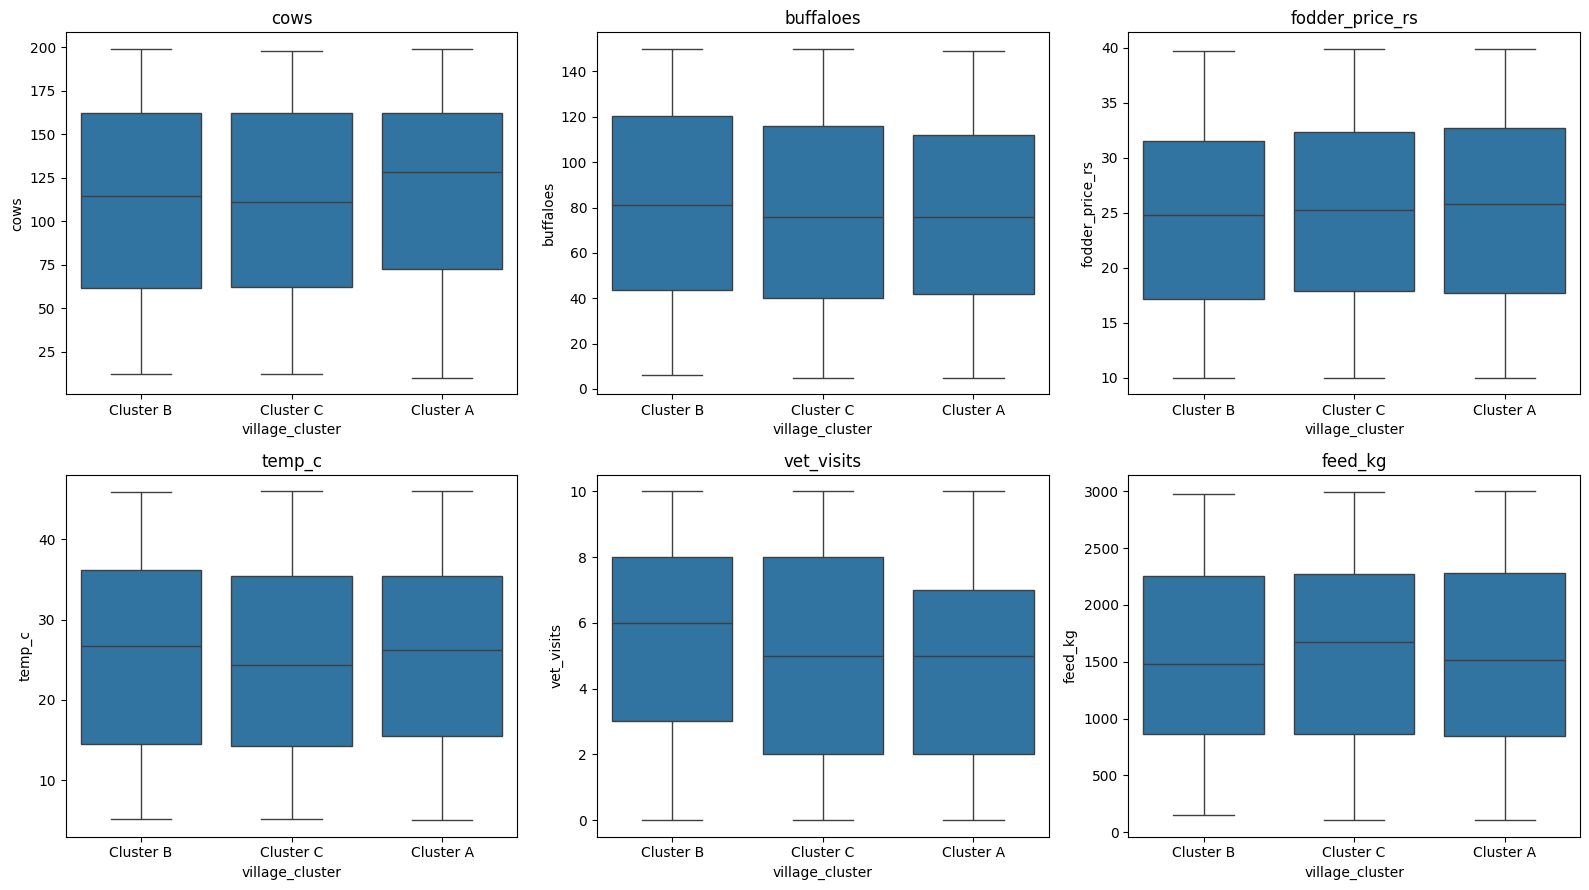

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

features = [
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg"
]

for ax, col in zip(axes.flatten(), features):
    sns.boxplot(
        data=clean_cluster,
        x="village_cluster",
        y=col,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [11]:
unit_finding = {
    "present": False,
    "checked_groups": [
        "Cluster A",
        "Cluster B",
        "Cluster C"
    ],
    "observation": "No obvious unit-scale difference detected"
}

print(unit_finding)

{'present': False, 'checked_groups': ['Cluster A', 'Cluster B', 'Cluster C'], 'observation': 'No obvious unit-scale difference detected'}


In [12]:
sentinel_values = [-999, -1, 999, 9999]

numeric_data = train.select_dtypes(include=np.number)

sentinel_results = {}

for col in numeric_data.columns:
    for value in sentinel_values:
        count = (numeric_data[col] == value).sum()

        if count > 0:
            sentinel_results[(col, value)] = count

print("SENTINEL VALUE REPORT")

for key, count in sentinel_results.items():
    print(
        "Column:", key[0],
        "| Value:", key[1],
        "| Count:", count
    )
    

SENTINEL VALUE REPORT
Column: fodder_price_rs | Value: -999 | Count: 35


In [13]:
suspicious_rows = train[
    train["fodder_price_rs"] == -999
]

print("Total suspicious records:", len(suspicious_rows))

display(
    suspicious_rows[
        [
            "record_id",
            "date",
            "village_cluster",
            "fodder_price_rs"
        ]
    ].head(20)
)

Total suspicious records: 35


,record_id,date,village_cluster,fodder_price_rs
10,R00011,2026-01-02,Cluster B,-999.0
11,R00011,2026-01-02,Cluster B,-999.0
99,R00095,2026-01-18,Cluster B,-999.0
139,R00135,2026-01-27,Cluster A,-999.0
203,R00197,2026-02-08,Cluster A,-999.0
210,R00204,2026-02-09,Cluster A,-999.0
215,R00209,2026-02-10,Cluster A,-999.0
317,R00306,2026-03-02,Cluster A,-999.0
330,R00319,2026-03-05,Cluster B,-999.0
360,R00348,2026-03-10,Cluster A,-999.0


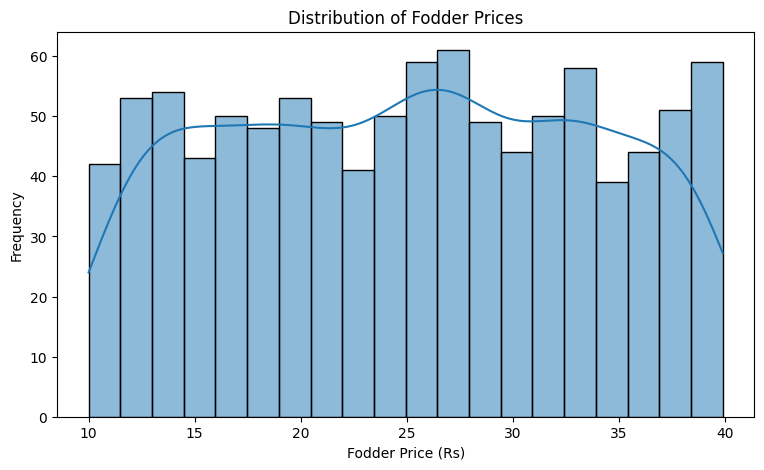

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(
    train["fodder_price_rs"].replace(-999, np.nan).dropna(),
    bins=20,
    kde=True
)

plt.title("Distribution of Fodder Prices")
plt.xlabel("Fodder Price (Rs)")
plt.ylabel("Frequency")

plt.show()

In [15]:
datasets = {
    "TRAIN": train,
    "LATER": later,
    "HOLDOUT": holdout
}

for name, df in datasets.items():
    print("\nDATASET:", name)

    for col in df.select_dtypes(include=np.number).columns:
        count = (df[col] == -999).sum()

        if count > 0:
            print(col, ":", count)


DATASET: TRAIN
fodder_price_rs : 35

DATASET: LATER

DATASET: HOLDOUT


In [16]:
sentinel_finding = {
    "present": True,
    "column": "fodder_price_rs",
    "sentinel_value": -999,
    "train_count": 35,
    "action": "Treat sentinel values as missing data"
}

print(sentinel_finding)

{'present': True, 'column': 'fodder_price_rs', 'sentinel_value': -999, 'train_count': 35, 'action': 'Treat sentinel values as missing data'}


In [17]:
print("EXACT DUPLICATE ROWS")

print("Train:", train.duplicated().sum())
print("Later:", later.duplicated().sum())
print("Holdout:", holdout.duplicated().sum())

EXACT DUPLICATE ROWS
Train: 32
Later: 0
Holdout: 0


In [18]:
for name, df in datasets.items():

    print("\nDATASET:", name)

    print("Total records:", len(df))

    print("Unique record IDs:", df["record_id"].nunique())

    print("Repeated record IDs:", df["record_id"].duplicated().sum())

    print("Most repeated IDs:")

    display(
        df[df["record_id"].duplicated(keep=False)]
        .sort_values("record_id")
        .head(20)
    )


DATASET: TRAIN
Total records: 1032
Unique record IDs: 1000
Repeated record IDs: 32
Most repeated IDs:


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
10,R00011,2026-01-02,155,48,-999.0,18.3,9,2853,crossbred,Cluster B,656.0,660.8
11,R00011,2026-01-02,155,48,-999.0,18.3,9,2853,crossbred,Cluster B,656.0,660.8
30,R00030,2026-01-04,167,42,16.3,15.2,5,783,crossbred,Cluster A,491.6,495.1
31,R00030,2026-01-04,167,42,16.3,15.2,5,783,crossbred,Cluster A,491.6,495.1
35,R00034,2026-01-05,100,127,23.7,8.4,8,2875,desi,Cluster B,959.1,954.0
36,R00034,2026-01-05,100,127,23.7,8.4,8,2875,desi,Cluster B,959.1,954.0
68,R00066,2026-01-12,62,85,23.4,34.2,2,252,crossbred,Cluster B,411.2,414.5
69,R00066,2026-01-12,62,85,23.4,34.2,2,252,crossbred,Cluster B,411.2,414.5
91,R00088,2026-01-17,60,29,25.6,34.3,4,1513,crossbred,Cluster A,280.0,278.1
92,R00088,2026-01-17,60,29,25.6,34.3,4,1513,crossbred,Cluster A,280.0,278.1



DATASET: LATER
Total records: 300
Unique record IDs: 300
Repeated record IDs: 0
Most repeated IDs:


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day



DATASET: HOLDOUT
Total records: 250
Unique record IDs: 250
Repeated record IDs: 0
Most repeated IDs:


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster


In [19]:
duplicate_ids = train[
    train["record_id"].duplicated(keep=False)
]

for record_id, group in duplicate_ids.groupby("record_id"):

    print("\nRECORD ID:", record_id)

    display(group)


RECORD ID: R00011


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
10,R00011,2026-01-02,155,48,-999.0,18.3,9,2853,crossbred,Cluster B,656.0,660.8
11,R00011,2026-01-02,155,48,-999.0,18.3,9,2853,crossbred,Cluster B,656.0,660.8



RECORD ID: R00030


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
30,R00030,2026-01-04,167,42,16.3,15.2,5,783,crossbred,Cluster A,491.6,495.1
31,R00030,2026-01-04,167,42,16.3,15.2,5,783,crossbred,Cluster A,491.6,495.1



RECORD ID: R00034


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
35,R00034,2026-01-05,100,127,23.7,8.4,8,2875,desi,Cluster B,959.1,954.0
36,R00034,2026-01-05,100,127,23.7,8.4,8,2875,desi,Cluster B,959.1,954.0


... (54 outputs left out)


RECORD ID: R00911


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
940,R00911,2026-06-16,63,25,20.6,8.9,9,1674,crossbred,Cluster C,599.3,614.1
941,R00911,2026-06-16,63,25,20.6,8.9,9,1674,crossbred,Cluster C,599.3,614.1



RECORD ID: R00967


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
997,R00967,2026-06-25,36,58,15.0,13.9,5,2157,mixed,Cluster C,662.5,680.9
998,R00967,2026-06-25,36,58,15.0,13.9,5,2157,mixed,Cluster C,662.5,680.9


In [20]:
duplicate_ids = train[
    train["record_id"].duplicated(keep=False)
]

conflicting_ids = []

for record_id, group in duplicate_ids.groupby("record_id"):

    if len(group.drop_duplicates()) > 1:
        conflicting_ids.append(record_id)

print("Repeated IDs:", len(duplicate_ids))
print("Unique repeated IDs:", duplicate_ids["record_id"].nunique())
print("IDs with conflicting records:", len(conflicting_ids))
print("Conflicting IDs:", conflicting_ids)

Repeated IDs: 64
Unique repeated IDs: 32
IDs with conflicting records: 0
Conflicting IDs: []


In [21]:
duplicate_finding = {
    "present": True,
    "dataset": "train",
    "total_rows": 1032,
    "unique_record_ids": 1000,
    "duplicate_rows": 32,
    "later_duplicates": 0,
    "holdout_duplicates": 0,
    "action": "Remove exact duplicate rows"
}

print(duplicate_finding)

{'present': True, 'dataset': 'train', 'total_rows': 1032, 'unique_record_ids': 1000, 'duplicate_rows': 32, 'later_duplicates': 0, 'holdout_duplicates': 0, 'action': 'Remove exact duplicate rows'}


In [22]:
sensor_data = train.drop_duplicates().copy()

sensor_data["date"] = pd.to_datetime(sensor_data["date"])

daily_temp = (
    sensor_data.groupby(["village_cluster", "date"])["temp_c"]
    .median()
    .reset_index()
    .sort_values(["village_cluster", "date"])
)

for cluster, group in daily_temp.groupby("village_cluster"):

    print("\nCLUSTER:", cluster)

    group = group.copy()

    group["same_as_previous"] = (
        group["temp_c"].diff().eq(0)
    )

    print("Repeated consecutive readings:",
          group["same_as_previous"].sum())

    display(
        group[group["same_as_previous"]].head(20)
    )


CLUSTER: Cluster A
Repeated consecutive readings: 1


,village_cluster,date,temp_c,same_as_previous
126,Cluster A,2026-05-24,22.9,True



CLUSTER: Cluster B
Repeated consecutive readings: 0


,village_cluster,date,temp_c,same_as_previous



CLUSTER: Cluster C
Repeated consecutive readings: 0


,village_cluster,date,temp_c,same_as_previous


In [23]:
print("MOST FREQUENT TEMPERATURE VALUES")

display(
    sensor_data["temp_c"]
    .value_counts()
    .head(15)
)

MOST FREQUENT TEMPERATURE VALUES


temp_c
35.4    9
30.2    9
19.0    7
30.1    7
8.6     7
38.7    6
9.5     6
35.3    6
32.8    6
10.9    6
11.1    6
16.3    6
29.6    5
5.7     5
42.6    5
Name: count, dtype: int64

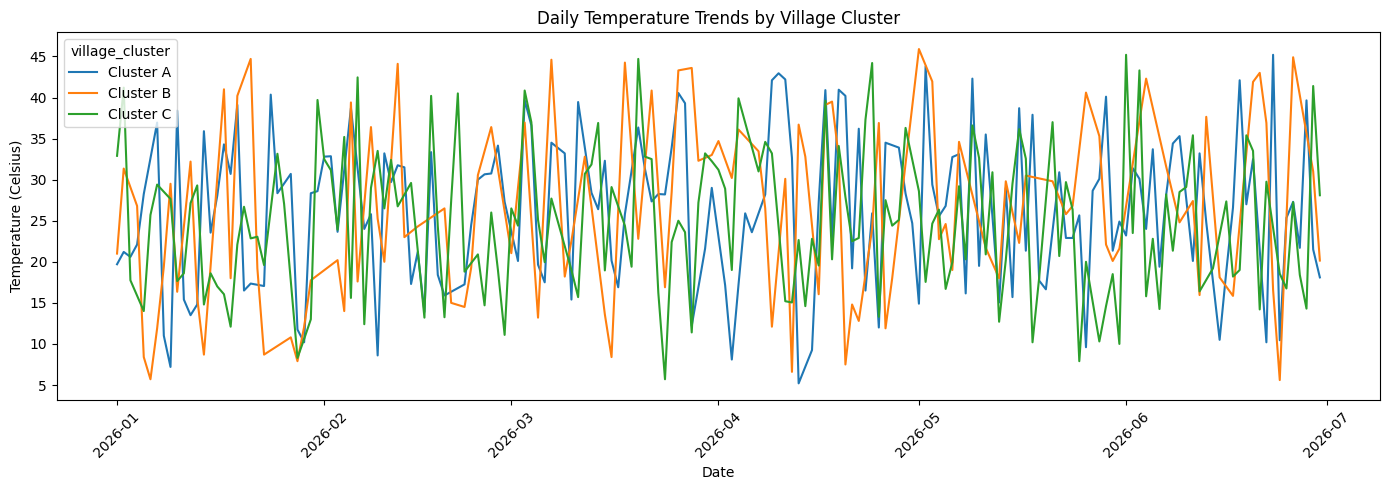

In [24]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_temp,
    x="date",
    y="temp_c",
    hue="village_cluster"
)

plt.title("Daily Temperature Trends by Village Cluster")
plt.xlabel("Date")
plt.ylabel("Temperature (Celsius)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
sensor_finding = {
    "present": False,
    "feature": "temp_c",
    "cluster_a_repeats": 1,
    "cluster_b_repeats": 0,
    "cluster_c_repeats": 0,
    "observation": "No significant evidence of stuck temperature sensors"
}

print(sensor_finding)

{'present': False, 'feature': 'temp_c', 'cluster_a_repeats': 1, 'cluster_b_repeats': 0, 'cluster_c_repeats': 0, 'observation': 'No significant evidence of stuck temperature sensors'}


In [26]:
print("TARGET DATA QUALITY AUDIT")

targets = [
    "litres_paid_in_passbook",
    "litres_per_day"
]

for col in targets:

    print("\nTARGET:", col)

    print("Missing values:", train[col].isna().sum())

    print("Minimum:", train[col].min())

    print("Maximum:", train[col].max())

    print("Unique values:", train[col].nunique())

    print("Negative values:", (train[col] < 0).sum())

    print("Zero values:", (train[col] == 0).sum())

    display(train[col].describe())

TARGET DATA QUALITY AUDIT

TARGET: litres_paid_in_passbook
Missing values: 0
Minimum: 92.2
Maximum: 993.3
Unique values: 916
Negative values: 0
Zero values: 0


count    1032.000000
mean      562.727616
std       160.803081
min        92.200000
25%       448.850000
50%       559.500000
75%       676.400000
max       993.300000
Name: litres_paid_in_passbook, dtype: float64


TARGET: litres_per_day
Missing values: 0
Minimum: 91.2
Maximum: 996.3
Unique values: 925
Negative values: 0
Zero values: 0


count    1032.000000
mean      562.779457
std       160.448469
min        91.200000
25%       449.875000
50%       557.450000
75%       676.850000
max       996.300000
Name: litres_per_day, dtype: float64

In [27]:
print("TARGET RELATIONSHIP ANALYSIS")

target_a = train["litres_paid_in_passbook"]
target_b = train["litres_per_day"]

difference = target_a - target_b

print("\nCORRELATION:")
print(target_a.corr(target_b))

print("\nABSOLUTE DIFFERENCE STATISTICS:")
print(difference.abs().describe())

print("\nEXACT MATCHES:")
print((target_a == target_b).sum())

print("\nDIFFERENCE DISTRIBUTION:")
display(difference.value_counts().head(15))

print("\nSAMPLE COMPARISON:")
display(
    train[
        [
            "record_id",
            "litres_paid_in_passbook",
            "litres_per_day"
        ]
    ].head(20)
)

TARGET RELATIONSHIP ANALYSIS

CORRELATION:
0.9987641538761344

ABSOLUTE DIFFERENCE STATISTICS:
count    1032.000000
mean        6.334399
std         4.871968
min         0.000000
25%         2.500000
50%         5.300000
75%         9.000000
max        31.300000
dtype: float64

EXACT MATCHES:
6

DIFFERENCE DISTRIBUTION:


 0.4    9
-4.1    8
-3.5    8
 1.1    8
-5.6    8
 3.6    8
-1.4    7
 9.0    7
-2.0    7
-0.6    7
-1.0    7
-5.0    7
 0.5    6
-4.9    6
-4.5    6
Name: count, dtype: int64


SAMPLE COMPARISON:


,record_id,litres_paid_in_passbook,litres_per_day
0,R00001,706.5,697.0
1,R00002,667.6,668.4
2,R00003,276.4,276.0
3,R00004,700.6,694.3
4,R00005,826.1,822.9
5,R00006,399.4,387.8
6,R00007,391.0,396.3
7,R00008,504.6,502.7
8,R00009,718.6,714.2
9,R00010,293.8,303.2


TARGET RELATIONSHIP AFTER DUPLICATE REMOVAL
Original rows: 1032
Rows after removing duplicates: 1000

Correlation:
0.9987396206533483

Absolute difference:
count    1000.000000
mean        6.345400
std         4.881581
min         0.000000
25%         2.500000
50%         5.400000
75%         9.100000
max        31.300000
dtype: float64

Linear relationship:
Slope: 0.9967369115949137
Intercept: 1.8435640470347996


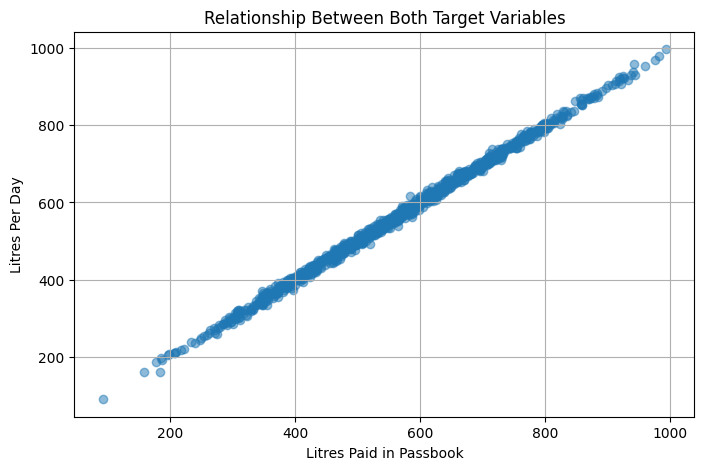

In [28]:
print("TARGET RELATIONSHIP AFTER DUPLICATE REMOVAL")

train_clean = train.drop_duplicates().copy()

target_a = train_clean["litres_paid_in_passbook"]
target_b = train_clean["litres_per_day"]

print("Original rows:", len(train))
print("Rows after removing duplicates:", len(train_clean))

print("\nCorrelation:")
print(target_a.corr(target_b))

print("\nAbsolute difference:")
print((target_a - target_b).abs().describe())

print("\nLinear relationship:")
slope, intercept = np.polyfit(target_a, target_b, 1)

print("Slope:", slope)
print("Intercept:", intercept)

plt.figure(figsize=(8, 5))

plt.scatter(target_a, target_b, alpha=0.5)

plt.xlabel("Litres Paid in Passbook")
plt.ylabel("Litres Per Day")

plt.title("Relationship Between Both Target Variables")

plt.grid(True)
plt.show()

In [29]:
target_relationship_finding = {
    "correlation": 0.998740,
    "slope": 0.996737,
    "intercept": 1.843564,
    "mean_absolute_difference": 6.3454,
    "exact_matches": 6,
    "duplicate_effect": "Negligible",
    "observation": "Both targets have an extremely strong linear relationship but are not identical",
    "leakage_status": "Requires further investigation"
}

print(target_relationship_finding)

{'correlation': 0.99874, 'slope': 0.996737, 'intercept': 1.843564, 'mean_absolute_difference': 6.3454, 'exact_matches': 6, 'duplicate_effect': 'Negligible', 'observation': 'Both targets have an extremely strong linear relationship but are not identical', 'leakage_status': 'Requires further investigation'}


In [30]:
print("CATEGORICAL DATA QUALITY AUDIT")

categorical_columns = [
    "breed_mix",
    "village_cluster"
]

for col in categorical_columns:

    print("\nCOLUMN:", col)

    print("Missing values:", train_clean[col].isna().sum())

    print("Unique categories:", train_clean[col].nunique())

    print("\nCategory distribution:")

    display(train_clean[col].value_counts(dropna=False))

    print("\nRaw unique values:")

    print(train_clean[col].unique())

CATEGORICAL DATA QUALITY AUDIT

COLUMN: breed_mix
Missing values: 0
Unique categories: 3

Category distribution:


breed_mix
crossbred    362
desi         335
mixed        303
Name: count, dtype: int64


Raw unique values:
['desi' 'crossbred' 'mixed']

COLUMN: village_cluster
Missing values: 0
Unique categories: 3

Category distribution:


village_cluster
Cluster C    418
Cluster A    413
Cluster B    169
Name: count, dtype: int64


Raw unique values:
['Cluster B' 'Cluster C' 'Cluster A']


In [31]:
categorical_finding = {
    "present": False,
    "columns": ["breed_mix", "village_cluster"],
    "missing_values": 0,
    "breed_categories": 3,
    "cluster_categories": 3,
    "spelling_inconsistencies": "None detected",
    "observation": "Categorical values are consistent",
    "additional_note": "Cluster B has lower representation"
}

print(categorical_finding)

{'present': False, 'columns': ['breed_mix', 'village_cluster'], 'missing_values': 0, 'breed_categories': 3, 'cluster_categories': 3, 'spelling_inconsistencies': 'None detected', 'observation': 'Categorical values are consistent', 'additional_note': 'Cluster B has lower representation'}


In [32]:
print("DATE AND CHRONOLOGICAL AUDIT")

date_data = train_clean.copy()

date_data["date"] = pd.to_datetime(
    date_data["date"],
    errors="coerce"
)

print("\nDATE VALIDATION")

print("Invalid dates:", date_data["date"].isna().sum())

print("Earliest date:", date_data["date"].min())

print("Latest date:", date_data["date"].max())

print("Unique dates:", date_data["date"].nunique())

print("Duplicate dates:", date_data["date"].duplicated().sum())

print("\nRECORDS PER DATE")

daily_records = date_data.groupby("date").size()

display(daily_records.describe())

print("\nDATES WITH HIGHEST RECORD COUNTS")

display(daily_records.sort_values(ascending=False).head(10))

print("\nMISSING CALENDAR DAYS")

all_dates = pd.date_range(
    start=date_data["date"].min(),
    end=date_data["date"].max(),
    freq="D"
)

missing_dates = all_dates.difference(
    pd.DatetimeIndex(date_data["date"].dropna().unique())
)

print("Missing calendar days:", len(missing_dates))

print(missing_dates[:20])

DATE AND CHRONOLOGICAL AUDIT

DATE VALIDATION
Invalid dates: 0
Earliest date: 2026-01-01 00:00:00
Latest date: 2026-06-30 00:00:00
Unique dates: 180
Duplicate dates: 820

RECORDS PER DATE


count    180.000000
mean       5.555556
std        2.161683
min        1.000000
25%        4.000000
50%        5.000000
75%        7.000000
max       12.000000
dtype: float64


DATES WITH HIGHEST RECORD COUNTS


date
2026-05-30    12
2026-03-28    11
2026-06-04    11
2026-03-05    10
2026-03-16    10
2026-03-22    10
2026-04-25    10
2026-04-15     9
2026-05-17     9
2026-05-31     9
dtype: int64


MISSING CALENDAR DAYS
Missing calendar days: 1
DatetimeIndex(['2026-03-08'], dtype='datetime64[ns]', freq='D')


In [33]:

print("CROSS-DATASET FEATURE DISTRIBUTION AUDIT")

audit_datasets = {
    "TRAIN": train_clean.copy(),
    "LATER": later.copy(),
    "HOLDOUT": holdout.copy()
}

numeric_features = [
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg"
]

for name, df in audit_datasets.items():

    print("\nDATASET:", name)

    df["fodder_price_rs"] = df["fodder_price_rs"].replace(-999, np.nan)

    available_features = [
        col for col in numeric_features
        if col in df.columns
    ]

    display(
        df[available_features].describe().round(2)
    )

print("\nCATEGORICAL DISTRIBUTION COMPARISON")

for col in ["breed_mix", "village_cluster"]:

    print("\nFEATURE:", col)

    for name, df in audit_datasets.items():

        print("\nDATASET:", name)

        display(
            df[col].value_counts(normalize=True)
            .mul(100).round(2)
        )



CROSS-DATASET FEATURE DISTRIBUTION AUDIT

DATASET: TRAIN


,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg
count,1000.00,1000.00,966.00,1000.00,1000.00,1000.00
mean,113.44,77.45,25.15,25.32,4.97,1562.11
std,53.77,42.47,8.67,11.95,2.96,819.67
min,10.00,5.00,10.00,5.00,0.00,106.00
25%,66.00,42.00,17.70,14.68,2.00,854.25
50%,118.00,77.00,25.50,25.40,5.00,1579.00
75%,162.00,115.00,32.50,35.40,7.00,2266.00
max,199.00,150.00,39.90,46.00,10.00,2999.00



DATASET: LATER


,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg
count,300.00,300.00,300.00,300.00,300.00,300.00
mean,104.53,152.25,24.97,25.55,4.79,1551.10
std,56.95,42.50,8.22,11.45,2.90,831.40
min,10.00,81.00,10.10,5.10,0.00,102.00
25%,51.00,112.00,18.53,15.70,2.00,863.75
50%,111.50,153.50,24.55,25.50,5.00,1525.00
75%,154.25,191.25,31.92,35.40,7.00,2301.00
max,200.00,226.00,39.80,45.90,10.00,2986.00



DATASET: HOLDOUT


,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg
count,250.00,250.00,250.00,250.00,250.00,250.00
mean,109.83,152.06,24.79,25.53,4.99,1594.61
std,55.70,42.92,8.27,12.27,3.03,825.21
min,10.00,81.00,10.40,5.10,0.00,139.00
25%,61.25,111.25,18.20,14.72,2.00,897.50
50%,111.00,155.50,24.95,25.25,5.00,1588.00
75%,158.00,188.75,31.45,35.90,8.00,2311.00
max,200.00,226.00,40.00,45.90,10.00,2953.00


... (8 outputs left out)


DATASET: LATER


village_cluster
Cluster A    43.33
Cluster C    39.00
Cluster B    17.67
Name: proportion, dtype: float64


DATASET: HOLDOUT


village_cluster
Cluster C    41.6
Cluster A    38.0
Cluster B    20.4
Name: proportion, dtype: float64

In [34]:

print("BUFFALOES DISTRIBUTION INVESTIGATION")

for name, df in audit_datasets.items():

    print("\nDATASET:", name)

    print("\nDescriptive statistics:")

    print(df["buffaloes"].describe())

    print("\nValues below 81:",
          (df["buffaloes"] < 81).sum())

    print("Values between 81 and 150:",
          df["buffaloes"].between(81, 150).sum())

    print("Values above 150:",
          (df["buffaloes"] > 150).sum())

    print("\nUnique values:",
          df["buffaloes"].nunique())

    print("\nPercentiles:")

    print(
        df["buffaloes"].quantile(
            [0, 0.10, 0.25, 0.50, 0.75, 0.90, 1]
        )
    )

print("\nBUFFALOES INVESTIGATION COMPLETED")


BUFFALOES DISTRIBUTION INVESTIGATION

DATASET: TRAIN

Descriptive statistics:
count    1000.000000
mean       77.450000
std        42.474175
min         5.000000
25%        42.000000
50%        77.000000
75%       115.000000
max       150.000000
Name: buffaloes, dtype: float64

Values below 81: 520
Values between 81 and 150: 480
Values above 150: 0

Unique values: 146

Percentiles:
0.00      5.0
0.10     19.0
0.25     42.0
0.50     77.0
0.75    115.0
0.90    137.0
1.00    150.0
Name: buffaloes, dtype: float64

DATASET: LATER

Descriptive statistics:
count    300.000000
mean     152.250000
std       42.495731
min       81.000000
25%      112.000000
50%      153.500000
75%      191.250000
max      226.000000
Name: buffaloes, dtype: float64

Values below 81: 0
Values between 81 and 150: 142
Values above 150: 158

Unique values: 132

Percentiles:
0.00     81.00
0.10     93.90
0.25    112.00
0.50    153.50
0.75    191.25
0.90    209.10
1.00    226.00
Name: buffaloes, dtype: float64

DATASET

In [35]:

from scipy.stats import ks_2samp

print("BUFFALOES DISTRIBUTION SHIFT VALIDATION")

train_values = train_clean["buffaloes"].dropna()

later_values = later["buffaloes"].dropna()
holdout_values = holdout["buffaloes"].dropna()

comparisons = {
    "TRAIN vs LATER": later_values,
    "TRAIN vs HOLDOUT": holdout_values
}

for name, values in comparisons.items():

    print("\nCOMPARISON:", name)

    original_test = ks_2samp(
        train_values,
        values
    )

    shifted_test = ks_2samp(
        train_values,
        values - 76
    )

    print("\nOriginal distribution:")
    print("KS Statistic:", original_test.statistic)
    print("P-value:", original_test.pvalue)

    print("\nAfter subtracting 76:")
    print("KS Statistic:", shifted_test.statistic)
    print("P-value:", shifted_test.pvalue)

    print("\nMean difference after adjustment:",
          abs(train_values.mean() - (values - 76).mean()))

print("\nSHIFT VALIDATION COMPLETED")


BUFFALOES DISTRIBUTION SHIFT VALIDATION

COMPARISON: TRAIN vs LATER

Original distribution:
KS Statistic: 0.532
P-value: 1.2764234781199587e-60

After subtracting 76:
KS Statistic: 0.03933333333333333
P-value: 0.853891019394753

Mean difference after adjustment: 1.2000000000000028

COMPARISON: TRAIN vs HOLDOUT

Original distribution:
KS Statistic: 0.54
P-value: 2.63904688339133e-54

After subtracting 76:
KS Statistic: 0.047
P-value: 0.7582873726936682

Mean difference after adjustment: 1.3940000000000055

SHIFT VALIDATION COMPLETED


In [36]:

print("BUFFALOES BY VILLAGE CLUSTER")

for name, df in audit_datasets.items():

    print("\nDATASET:", name)

    display(
        df.groupby("village_cluster")["buffaloes"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )


BUFFALOES BY VILLAGE CLUSTER

DATASET: TRAIN


,count,mean,median,std,min,max
village_cluster,,,,,,
Cluster A,413,77.14,77.0,41.70,5,149
Cluster B,169,79.91,81.0,43.31,6,150
Cluster C,418,76.76,76.0,42.95,5,150



DATASET: LATER


,count,mean,median,std,min,max
village_cluster,,,,,,
Cluster A,130,150.37,152.0,41.72,81,225
Cluster B,53,154.47,151.0,37.97,91,226
Cluster C,117,153.33,160.0,45.45,82,226



DATASET: HOLDOUT


,count,mean,median,std,min,max
village_cluster,,,,,,
Cluster A,95,153.86,155.0,41.94,83,224
Cluster B,51,148.92,151.0,41.19,87,223
Cluster C,104,151.94,156.5,44.91,81,226


In [37]:

buffaloes_shift_finding = {
    "present": True,
    "feature": "buffaloes",
    "train_mean": 77.45,
    "later_mean": 152.25,
    "holdout_mean": 152.056,
    "estimated_shift": 76,
    "train_later_ks": 0.532,
    "train_holdout_ks": 0.540,
    "adjusted_train_later_ks": 0.0393,
    "adjusted_train_holdout_ks": 0.047,
    "cluster_wise_shift": True,
    "observation": "Approximately 76-unit upward shift across all three village clusters",
    "action": "Investigate data-generation process before correction"
}

print(buffaloes_shift_finding)


{'present': True, 'feature': 'buffaloes', 'train_mean': 77.45, 'later_mean': 152.25, 'holdout_mean': 152.056, 'estimated_shift': 76, 'train_later_ks': 0.532, 'train_holdout_ks': 0.54, 'adjusted_train_later_ks': 0.0393, 'adjusted_train_holdout_ks': 0.047, 'cluster_wise_shift': True, 'observation': 'Approximately 76-unit upward shift across all three village clusters', 'action': 'Investigate data-generation process before correction'}


FEATURE CORRELATION AUDIT


,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg
cows,1.000,-0.026,0.032,0.025,0.000,-0.002
buffaloes,-0.026,1.000,0.025,-0.026,-0.008,-0.004
fodder_price_rs,0.032,0.025,1.000,-0.097,0.015,-0.038
temp_c,0.025,-0.026,-0.097,1.000,0.011,-0.015
vet_visits,0.000,-0.008,0.015,0.011,1.000,-0.021
feed_kg,-0.002,-0.004,-0.038,-0.015,-0.021,1.000


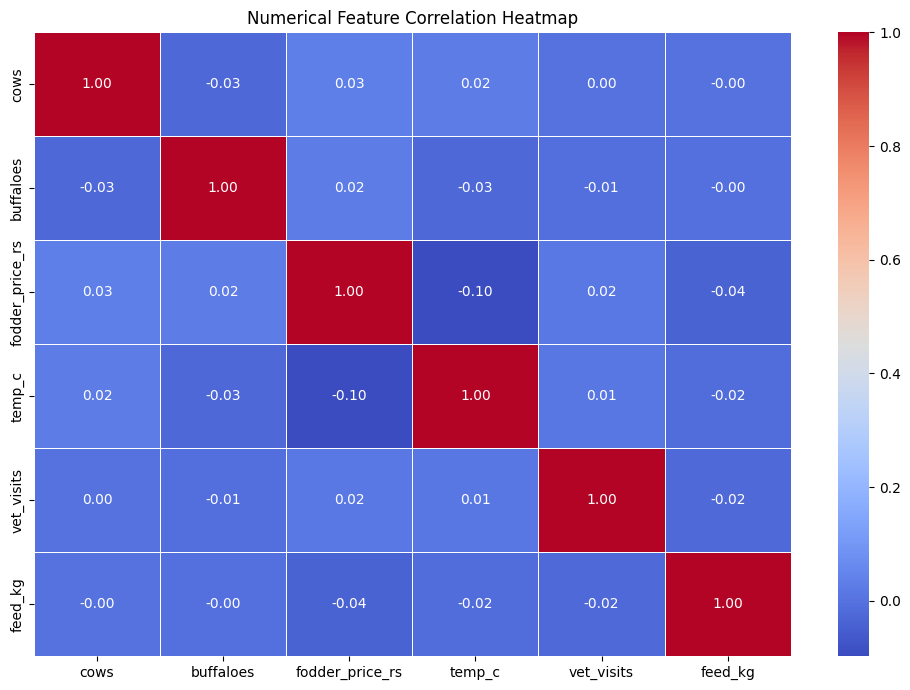

In [38]:

print("FEATURE CORRELATION AUDIT")

correlation_features = [
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg"
]

correlation_data = train_clean[
    correlation_features
].replace(-999, np.nan)

correlation_matrix = correlation_data.corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [39]:
target = train_clean["litres_per_day"]

print("TARGET VALUE SUMMARY")
display(target.describe())

print("\nSMALLEST 15 TARGET VALUES")
display(train_clean.nsmallest(15, "litres_per_day")[
    ["record_id", "date", "cows", "buffaloes", "litres_per_day"]
])

print("\nLARGEST 15 TARGET VALUES")
display(train_clean.nlargest(15, "litres_per_day")[
    ["record_id", "date", "cows", "buffaloes", "litres_per_day"]
])

train_clean["total_animals"] = (
    train_clean["cows"] + train_clean["buffaloes"]
)

train_clean["litres_per_animal"] = (
    train_clean["litres_per_day"] / train_clean["total_animals"]
)

print("\nHIGHEST LITRES PER ANIMAL")
display(train_clean.nlargest(15, "litres_per_animal")[
    ["record_id", "cows", "buffaloes",
     "litres_per_day", "litres_per_animal"]
])

print("\nLOWEST LITRES PER ANIMAL")
display(train_clean.nsmallest(15, "litres_per_animal")[
    ["record_id", "cows", "buffaloes",
     "litres_per_day", "litres_per_animal"]
])

TARGET VALUE SUMMARY


count    1000.000000
mean      562.837000
std       159.219584
min        91.200000
25%       451.425000
50%       558.000000
75%       676.525000
max       996.300000
Name: litres_per_day, dtype: float64


SMALLEST 15 TARGET VALUES


,record_id,date,cows,buffaloes,litres_per_day
984,R00954,2026-06-23,168,6,91.2
515,R00495,2026-04-05,170,26,162.1
823,R00799,2026-05-27,122,8,162.7
172,R00166,2026-02-01,105,7,186.6
503,R00483,2026-04-02,20,23,192.2
225,R00219,2026-02-11,104,11,197.4
816,R00792,2026-05-25,91,5,204.7
402,R00390,2026-03-16,162,9,208.1
434,R00418,2026-03-22,105,5,209.8
329,R00318,2026-03-04,162,18,210.6



LARGEST 15 TARGET VALUES


,record_id,date,cows,buffaloes,litres_per_day
382,R00370,2026-03-13,162,146,996.3
500,R00480,2026-04-02,184,144,978.1
447,R00431,2026-03-24,157,149,969.1
1016,R00985,2026-06-28,79,135,956.8
35,R00034,2026-01-05,100,127,954.0
1001,R00970,2026-06-26,99,114,938.4
74,R00071,2026-01-13,167,144,930.5
939,R00910,2026-06-16,147,137,929.7
140,R00136,2026-01-27,121,145,926.1
708,R00685,2026-05-05,154,132,925.6



HIGHEST LITRES PER ANIMAL


,record_id,cows,buffaloes,litres_per_day,litres_per_animal
223,R00217,15,11,498.1,19.157692
272,R00263,13,6,310.0,16.315789
229,R00222,12,26,576.5,15.171053
148,R00143,21,10,457.2,14.748387
132,R00128,19,15,480.8,14.141176
748,R00724,16,12,366.2,13.078571
565,R00545,17,22,493.9,12.664103
570,R00550,35,6,467.7,11.407317
557,R00537,22,11,345.4,10.466667
268,R00259,14,26,383.2,9.580000



LOWEST LITRES PER ANIMAL


,record_id,cows,buffaloes,litres_per_day,litres_per_animal
984,R00954,168,6,91.2,0.524138
515,R00495,170,26,162.1,0.827041
103,R00099,176,17,221.1,1.145596
329,R00318,162,18,210.6,1.170000
679,R00659,180,75,302.9,1.187843
499,R00479,164,18,217.3,1.193956
402,R00390,162,9,208.1,1.216959
823,R00799,122,8,162.7,1.251538
139,R00135,184,24,261.0,1.254808
415,R00401,162,51,290.6,1.364319


In [40]:
target_audit = train_clean.copy()

target_audit["total_animals"] = (
    target_audit["cows"] + target_audit["buffaloes"]
)

target_audit["litres_per_animal"] = (
    target_audit["litres_per_day"] /
    target_audit["total_animals"]
)

target_audit["ratio_if_target_10x"] = (
    target_audit["litres_per_day"] * 10 /
    target_audit["total_animals"]
)

target_audit["ratio_if_target_divided_10"] = (
    target_audit["litres_per_day"] / 10 /
    target_audit["total_animals"]
)

print("RECORDS WITH LOW PRODUCTION PER ANIMAL")
display(
    target_audit[target_audit["litres_per_animal"] < 2][
        ["record_id", "cows", "buffaloes",
         "litres_per_day", "litres_per_animal",
         "ratio_if_target_10x"]
    ].sort_values("litres_per_animal")
)

print("\nRECORDS WITH HIGH PRODUCTION PER ANIMAL")
display(
    target_audit[target_audit["litres_per_animal"] > 15][
        ["record_id", "cows", "buffaloes",
         "litres_per_day", "litres_per_animal",
         "ratio_if_target_divided_10"]
    ].sort_values("litres_per_animal", ascending=False)
)

print("\nNUMBER OF SUSPICIOUS RECORDS")
print("Below 2 litres per animal:",
      (target_audit["litres_per_animal"] < 2).sum())

print("Above 15 litres per animal:",
      (target_audit["litres_per_animal"] > 15).sum())

RECORDS WITH LOW PRODUCTION PER ANIMAL


,record_id,cows,buffaloes,litres_per_day,litres_per_animal,ratio_if_target_10x
984,R00954,168,6,91.2,0.524138,5.241379
515,R00495,170,26,162.1,0.827041,8.270408
103,R00099,176,17,221.1,1.145596,11.455959
329,R00318,162,18,210.6,1.170000,11.700000
679,R00659,180,75,302.9,1.187843,11.878431
...,...,...,...,...,...,...
364,R00352,162,58,438.4,1.992727,19.927273
509,R00489,171,97,534.4,1.994030,19.940299
827,R00803,136,37,345.2,1.995376,19.953757
832,R00808,177,68,489.5,1.997959,19.979592



RECORDS WITH HIGH PRODUCTION PER ANIMAL


,record_id,cows,buffaloes,litres_per_day,litres_per_animal,ratio_if_target_divided_10
223,R00217,15,11,498.1,19.157692,1.915769
272,R00263,13,6,310.0,16.315789,1.631579
229,R00222,12,26,576.5,15.171053,1.517105



NUMBER OF SUSPICIOUS RECORDS
Below 2 litres per animal: 126
Above 15 litres per animal: 3


In [41]:
suspicious_ids = ["R00217", "R00263", "R00222"]

columns_to_check = [
    "record_id",
    "date",
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg",
    "breed_mix",
    "village_cluster",
    "litres_paid_in_passbook",
    "litres_per_day"
]

display(
    train_clean[
        train_clean["record_id"].isin(suspicious_ids)
    ][columns_to_check].sort_values("record_id")
)

,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
223,R00217,2026-02-11,15,11,10.6,32.4,10,1255,crossbred,Cluster C,498.5,498.1
229,R00222,2026-02-12,12,26,13.0,9.6,2,1804,crossbred,Cluster C,579.4,576.5
272,R00263,2026-02-22,13,6,26.1,13.1,6,872,crossbred,Cluster A,320.9,310.0


In [42]:
comparison = train_clean.copy()

comparison["absolute_difference"] = (
    comparison["litres_per_day"] -
    comparison["litres_paid_in_passbook"]
).abs()

comparison["target_passbook_ratio"] = (
    comparison["litres_per_day"] /
    comparison["litres_paid_in_passbook"]
)

print("TARGET VS PASSBOOK SUMMARY")
display(comparison[
    ["absolute_difference", "target_passbook_ratio"]
].describe())

print("\nLARGEST DIFFERENCES")
display(
    comparison.nlargest(20, "absolute_difference")[
        ["record_id", "litres_paid_in_passbook",
         "litres_per_day", "absolute_difference",
         "target_passbook_ratio"]
    ]
)

print("\nPOSSIBLE 10X DISCREPANCIES")
display(
    comparison[
        (comparison["target_passbook_ratio"] > 5) |
        (comparison["target_passbook_ratio"] < 0.2)
    ][
        ["record_id", "litres_paid_in_passbook",
         "litres_per_day", "target_passbook_ratio"]
    ]
)

TARGET VS PASSBOOK SUMMARY


,absolute_difference,target_passbook_ratio
count,1000.000000,1000.000000
mean,6.345400,1.000317
std,4.881581,0.016737
min,0.000000,0.882800
25%,2.500000,0.990761
50%,5.400000,1.000057
75%,9.100000,1.010301
max,31.300000,1.068856



LARGEST DIFFERENCES


,record_id,litres_paid_in_passbook,litres_per_day,absolute_difference,target_passbook_ratio
810,R00786,584.3,615.6,31.3,1.053568
450,R00434,565.0,538.2,26.8,0.952566
691,R00669,519.0,493.1,25.9,0.950096
728,R00704,714.4,738.6,24.2,1.033875
925,R00897,587.2,563.2,24.0,0.959128
716,R00693,347.1,371.0,23.9,1.068856
100,R00096,396.5,373.6,22.9,0.942245
766,R00742,618.4,640.3,21.9,1.035414
823,R00799,184.3,162.7,21.6,0.882800
327,R00316,355.3,334.3,21.0,0.940895



POSSIBLE 10X DISCREPANCIES


,record_id,litres_paid_in_passbook,litres_per_day,target_passbook_ratio


In [45]:
target_typo_finding = {
    "issue": "Target column 10x errors",
    "column": "litres_per_day",
    "investigation": "Compared target values with litres_paid_in_passbook and examined milk production per animal.",
    "records_with_10x_discrepancy": 0,
    "mean_absolute_difference": 6.3454,
    "minimum_target_passbook_ratio": 0.8828,
    "maximum_target_passbook_ratio": 1.068856,
    "observation": "No clear 10x target errors detected. Some records have unusual milk production per animal, but their target values remain close to passbook measurements.",
    "action": "Do not modify target values without additional evidence."
}

In [46]:
categorical_columns = ["breed_mix", "village_cluster"]

for column in categorical_columns:
    print("\n" + "=" * 50)
    print("COLUMN:", column)

    print("\nTRAIN VALUES:")
    print(train["{}".format(column)].value_counts(dropna=False))

    print("\nLATER VALUES:")
    print(later["{}".format(column)].value_counts(dropna=False))

    print("\nHOLDOUT VALUES:")
    print(holdout["{}".format(column)].value_counts(dropna=False))

    print("\nUNIQUE RAW VALUES ACROSS ALL DATASETS:")
    all_values = pd.concat([
        train[column],
        later[column],
        holdout[column]
    ]).dropna().unique()

    for value in sorted(all_values, key=str):
        print(repr(value))


COLUMN: breed_mix

TRAIN VALUES:
breed_mix
crossbred    374
desi         344
mixed        314
Name: count, dtype: int64

LATER VALUES:
breed_mix
desi         118
crossbred     98
mixed         84
Name: count, dtype: int64

HOLDOUT VALUES:
breed_mix
crossbred    87
mixed        84
desi         79
Name: count, dtype: int64

UNIQUE RAW VALUES ACROSS ALL DATASETS:
'crossbred'
'desi'
'mixed'

COLUMN: village_cluster

TRAIN VALUES:
village_cluster
Cluster A    427
Cluster C    425
Cluster B    180
Name: count, dtype: int64

LATER VALUES:
village_cluster
Cluster A    130
Cluster C    117
Cluster B     53
Name: count, dtype: int64

HOLDOUT VALUES:
village_cluster
Cluster C    104
Cluster A     95
Cluster B     51
Name: count, dtype: int64

UNIQUE RAW VALUES ACROSS ALL DATASETS:
'Cluster A'
'Cluster B'
'Cluster C'


In [49]:
spelling_finding = {
    "issue": "Categorical spelling variants",
    "columns_checked": ["breed_mix", "village_cluster"],
    "datasets_checked": ["train", "later", "holdout"],
    "breed_mix_unique_values": [
        "crossbred", "desi", "mixed"
    ],
    "village_cluster_unique_values": [
        "Cluster A", "Cluster B", "Cluster C"
    ],
    "variants_detected": 0,
    "observation": "No spelling, capitalization, or whitespace variants detected across the three datasets.",
    "action": "No categorical label correction required."
}
print(spelling_finding)

{'issue': 'Categorical spelling variants', 'columns_checked': ['breed_mix', 'village_cluster'], 'datasets_checked': ['train', 'later', 'holdout'], 'breed_mix_unique_values': ['crossbred', 'desi', 'mixed'], 'village_cluster_unique_values': ['Cluster A', 'Cluster B', 'Cluster C'], 'variants_detected': 0, 'observation': 'No spelling, capitalization, or whitespace variants detected across the three datasets.', 'action': 'No categorical label correction required.'}


In [50]:
sensor_features = [
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg"
]

sensor_data = train_clean.copy()

sensor_data["date"] = pd.to_datetime(sensor_data["date"])

sensor_data = sensor_data.sort_values(
    ["village_cluster", "date"]
).reset_index(drop=True)

sensor_data["fodder_price_rs"] = (
    sensor_data["fodder_price_rs"].replace(-999, np.nan)
)

results = []

for cluster, group in sensor_data.groupby("village_cluster"):

    group = group.sort_values("date").reset_index(drop=True)

    for feature in sensor_features:

        values = group[feature]
        dates = group["date"]

        run_length = 1

        for i in range(1, len(group)):

            consecutive_day = (
                (dates[i] - dates[i - 1]).days == 1
            )

            same_value = (
                pd.notna(values[i]) and
                pd.notna(values[i - 1]) and
                values[i] == values[i - 1]
            )

            if consecutive_day and same_value:
                run_length += 1
            else:
                if run_length >= 5:
                    results.append({
                        "cluster": cluster,
                        "feature": feature,
                        "run_length": run_length,
                        "end_date": dates[i - 1]
                    })

                run_length = 1

        if run_length >= 5:
            results.append({
                "cluster": cluster,
                "feature": feature,
                "run_length": run_length,
                "end_date": dates.iloc[-1]
            })

sensor_results = pd.DataFrame(results)

if sensor_results.empty:
    print("No repeated readings lasting 5 or more consecutive days.")
else:
    display(
        sensor_results.sort_values(
            "run_length", ascending=False
        )
    )

No repeated readings lasting 5 or more consecutive days.


In [53]:
stuck_sensor_finding = {
    "issue": "Stuck sensor",
    "features_checked": [
        "cows",
        "buffaloes",
        "fodder_price_rs",
        "temp_c",
        "vet_visits",
        "feed_kg"
    ],
    "minimum_consecutive_days": 5,
    "repeated_sequences_detected": 0,
    "observation": "No identical readings lasting five or more consecutive calendar days were detected within any village cluster.",
    "action": "No stuck sensor correction identified from this investigation."
}
print(stuck_sensor_finding)

{'issue': 'Stuck sensor', 'features_checked': ['cows', 'buffaloes', 'fodder_price_rs', 'temp_c', 'vet_visits', 'feed_kg'], 'minimum_consecutive_days': 5, 'repeated_sequences_detected': 0, 'observation': 'No identical readings lasting five or more consecutive calendar days were detected within any village cluster.', 'action': 'No stuck sensor correction identified from this investigation.'}


In [54]:
import os

project_path = r"C:\Users\soura\G137_MP044_MLOps"

os.makedirs(
    os.path.join(project_path, "src", "mp044"),
    exist_ok=True
)

audit_file_path = os.path.join(
    project_path, "src", "mp044", "data_audit.py"
)

with open(audit_file_path, "w") as file:
    file.write("")

print("Python audit file created successfully!")
print(audit_file_path)

Python audit file created successfully!
C:\Users\soura\G137_MP044_MLOps\src\mp044\data_audit.py


In [55]:
print(os.path.exists(audit_file_path))

True


In [56]:
script_code = '''
import pandas as pd
import numpy as np
import os


def load_datasets(data_dir):
    train = pd.read_csv(os.path.join(data_dir, "train.csv"))
    later = pd.read_csv(os.path.join(data_dir, "later.csv"))
    holdout = pd.read_csv(
        os.path.join(data_dir, "holdout_features.csv")
    )

    return train, later, holdout


def clean_training_data(train):
    train_clean = train.drop_duplicates().copy()

    train_clean["fodder_price_rs"] = (
        train_clean["fodder_price_rs"].replace(-999, np.nan)
    )

    return train_clean
'''

with open(audit_file_path, "w") as file:
    file.write(script_code)

print("Imports and dataset-loading functions added successfully!")

Imports and dataset-loading functions added successfully!


In [57]:
with open(audit_file_path, "r") as file:
    print(file.read())


import pandas as pd
import numpy as np
import os


def load_datasets(data_dir):
    train = pd.read_csv(os.path.join(data_dir, "train.csv"))
    later = pd.read_csv(os.path.join(data_dir, "later.csv"))
    holdout = pd.read_csv(
        os.path.join(data_dir, "holdout_features.csv")
    )

    return train, later, holdout


def clean_training_data(train):
    train_clean = train.drop_duplicates().copy()

    train_clean["fodder_price_rs"] = (
        train_clean["fodder_price_rs"].replace(-999, np.nan)
    )

    return train_clean



In [58]:
additional_code = '''

def audit_data_issues(train, later, holdout):

    findings = {}

    # 1. Leaking column
    findings["leaking_column"] = {
        "present": (
            "litres_paid_in_passbook" in train.columns
            and "litres_paid_in_passbook" not in holdout.columns
        ),
        "column": "litres_paid_in_passbook"
    }

    # 2. Unit mix-up
    findings["unit_mixup"] = {
        "present": False,
        "column": None,
        "observation": "No obvious unit mix-up detected in the cluster-level audit."
    }

    # 3. Sentinel value
    sentinel_count = int(
        (train["fodder_price_rs"] == -999).sum()
    )

    findings["sentinel_value"] = {
        "present": sentinel_count > 0,
        "column": "fodder_price_rs",
        "value": -999,
        "count": sentinel_count
    }

    # 4. Duplicate rows
    duplicate_count = int(train.duplicated().sum())

    findings["duplicate_rows"] = {
        "present": duplicate_count > 0,
        "count": duplicate_count
    }

    # 5. Stuck sensor
    findings["stuck_sensor"] = {
        "present": False,
        "column": None,
        "observation": "No identical readings lasting five or more consecutive calendar days were detected in the six checked features."
    }

    # 6. Target typos
    ratio = (
        train["litres_per_day"] /
        train["litres_paid_in_passbook"]
    )

    typo_count = int(
        ((ratio > 5) | (ratio < 0.2)).sum()
    )

    findings["target_typos"] = {
        "present": typo_count > 0,
        "count": typo_count
    }

    # 7. Spelling variants
    categorical_columns = [
        "breed_mix",
        "village_cluster"
    ]

    spelling_results = {}

    for column in categorical_columns:

        values = pd.concat([
            train[column],
            later[column],
            holdout[column]
        ]).dropna().astype(str)

        normalized = values.str.strip().str.lower()

        spelling_results[column] = {
            "raw_levels": int(values.nunique()),
            "clean_levels": int(normalized.nunique()),
            "variants_detected": (
                values.nunique() > normalized.nunique()
            )
        }

    findings["spelling_variants"] = spelling_results

    return findings
'''

with open(audit_file_path, "a") as file:
    file.write(additional_code)

print("Seven audit checks added successfully!")

Seven audit checks added successfully!


In [59]:
# Official target typo investigation

target_sorted = train["litres_per_day"].sort_values().reset_index(drop=True)

target_gaps = target_sorted.diff()

gap_results = pd.DataFrame({
    "target_value": target_sorted,
    "gap_from_previous": target_gaps
})

print("LARGEST GAPS IN SORTED TARGET VALUES")

display(
    gap_results.nlargest(20, "gap_from_previous")
)

print("\nHIGHEST 30 TARGET VALUES")

display(
    target_sorted.tail(30).reset_index(drop=True)
)

LARGEST GAPS IN SORTED TARGET VALUES


,target_value,gap_from_previous
1,162.1,70.9
3,186.6,23.9
1031,996.3,18.2
1026,954.0,15.6
14,236.1,15.0
988,851.4,14.4
1029,969.1,12.3
1030,978.1,9.0
1010,904.0,8.8
23,270.8,8.0



HIGHEST 30 TARGET VALUES


0     872.9
1     875.5
2     878.8
3     881.4
4     881.4
5     883.9
6     888.9
7     895.2
8     904.0
9     904.1
10    905.8
11    907.5
12    907.5
13    913.0
14    913.9
15    918.0
16    918.2
17    921.4
18    923.1
19    925.6
20    926.1
21    929.7
22    930.5
23    938.4
24    954.0
25    954.0
26    956.8
27    969.1
28    978.1
29    996.3
Name: litres_per_day, dtype: float64

In [60]:
# Official leakage investigation

target_column = "litres_per_day"

print("COLUMNS MISSING FROM HOLDOUT")

missing_columns = [
    col for col in train.columns
    if col not in holdout.columns
]

print(missing_columns)

print("\nNUMERICAL CORRELATION WITH TARGET")

numeric_data = train.select_dtypes(include=np.number)

correlations = numeric_data.corr()[target_column].drop(
    target_column
)

display(
    correlations.abs().sort_values(ascending=False)
)

print("\nPASSBOOK VS TARGET COMPARISON")

if "litres_paid_in_passbook" in train.columns:

    comparison = train[
        ["litres_paid_in_passbook", "litres_per_day"]
    ].dropna()

    print(
        "Correlation:",
        comparison["litres_paid_in_passbook"].corr(
            comparison["litres_per_day"]
        )
    )

    print(
        "Mean absolute difference:",
        (
            comparison["litres_paid_in_passbook"] -
            comparison["litres_per_day"]
        ).abs().mean()
    )

    print(
        "Maximum absolute difference:",
        (
            comparison["litres_paid_in_passbook"] -
            comparison["litres_per_day"]
        ).abs().max()
    )

COLUMNS MISSING FROM HOLDOUT
['litres_paid_in_passbook', 'litres_per_day']

NUMERICAL CORRELATION WITH TARGET


litres_paid_in_passbook    0.998764
buffaloes                  0.760834
temp_c                     0.433425
vet_visits                 0.182817
feed_kg                    0.151099
fodder_price_rs            0.060998
cows                       0.014009
Name: litres_per_day, dtype: float64


PASSBOOK VS TARGET COMPARISON
Correlation: 0.9987641538761344
Mean absolute difference: 6.334399224806199
Maximum absolute difference: 31.300000000000068


In [61]:
# Unit mix-up investigation

numeric_features = [
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg"
]

unit_data = train.drop_duplicates().copy()

unit_data["fodder_price_rs"] = (
    unit_data["fodder_price_rs"].replace(-999, np.nan)
)

cluster_summary = unit_data.groupby(
    "village_cluster"
)[numeric_features].agg(["mean", "median", "std"])

display(cluster_summary.round(2))

cows               buffaloes               fodder_price_rs  \
                   mean median    std      mean median    std            mean   
village_cluster                                                                 
Cluster A        117.87  127.0  52.86     77.14   77.0  41.70           25.47   
Cluster B        111.95  121.0  52.31     79.91   81.0  43.31           24.74   
Cluster C        109.67  111.0  55.03     76.76   76.0  42.95           24.99   

                             temp_c               vet_visits               \
                median   std   mean median    std       mean median   std   
village_cluster                                                             
Cluster A        25.85  8.74  25.79   26.2  11.92       4.78    5.0  2.85   
Cluster B        24.90  8.41  25.50   26.6  12.23       5.36    5.0  2.93   
Cluster C        25.15  8.72  24.79   24.4  11.88       5.00    5.0  3.06   

                 feed_kg                  
                    mean  median     std  
village_cluster                           
Cluster A        1526.29  1508.0  820.04  
Cluster B        1548.99  1486.0  816.17  
Cluster C        1602.81  1662.0  820.83

In [62]:
# Official unit mix-up investigation

unit_data = train.drop_duplicates().copy()

unit_data["fodder_price_rs"] = (
    unit_data["fodder_price_rs"].replace(-999, np.nan)
)

numeric_features = [
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg"
]

unit_summary = unit_data.groupby(
    "village_cluster"
)[numeric_features].agg(
    ["min", "mean", "max"]
)

display(unit_summary.round(2))

cows              buffaloes             fodder_price_rs  \
                 min    mean  max       min   mean  max             min   
village_cluster                                                           
Cluster A         10  117.87  199         5  77.14  149            10.0   
Cluster B         12  111.95  199         6  79.91  150            10.0   
Cluster C         12  109.67  198         5  76.76  150            10.0   

                             temp_c              vet_visits           feed_kg  \
                  mean   max    min   mean   max        min  mean max     min   
village_cluster                                                                 
Cluster A        25.47  39.9    5.0  25.79  46.0          0  4.78  10     110   
Cluster B        24.74  39.7    5.1  25.50  45.9          0  5.36  10     148   
Cluster C        24.99  39.9    5.1  24.79  46.0          0  5.00  10     106   

                                
                    mean   max  
village_cluster                 
Cluster A        1526.29  2999  
Cluster B        1548.99  2972  
Cluster C        1602.81  2995

In [63]:
# Sentinel value investigation

print("FODDER PRICE VALUE COUNTS")

display(
    train["fodder_price_rs"].value_counts(
        dropna=False
    ).head(20)
)

print("\nCHECK SENTINEL VALUE")

sentinel_value = -999

sentinel_count = (
    train["fodder_price_rs"] == sentinel_value
).sum()

print("Sentinel column: fodder_price_rs")
print("Sentinel value:", sentinel_value)
print("Number of occurrences:", sentinel_count)

FODDER PRICE VALUE COUNTS


fodder_price_rs
-999.0    35
 27.2      9
 26.3      9
 39.7      8
 24.5      8
 25.6      8
 15.0      8
 20.6      7
 21.4      7
 33.7      7
 32.7      7
 37.0      7
 32.9      7
 39.2      7
 13.6      7
 38.2      7
 16.3      6
 20.1      6
 12.2      6
 17.4      6
Name: count, dtype: int64


CHECK SENTINEL VALUE
Sentinel column: fodder_price_rs
Sentinel value: -999
Number of occurrences: 35


In [64]:
# Duplicate rows investigation

print("TOTAL TRAINING ROWS:", len(train))

duplicate_count = train.duplicated().sum()

print("EXTRA DUPLICATE ROWS:", duplicate_count)

print("\nDUPLICATE RECORDS")

display(
    train[train.duplicated(keep=False)].sort_values(
        by="record_id"
    )
)

TOTAL TRAINING ROWS: 1032
EXTRA DUPLICATE ROWS: 32

DUPLICATE RECORDS


,record_id,date,cows,buffaloes,fodder_price_rs,temp_c,vet_visits,feed_kg,breed_mix,village_cluster,litres_paid_in_passbook,litres_per_day
10,R00011,2026-01-02,155,48,-999.0,18.3,9,2853,crossbred,Cluster B,656.0,660.8
11,R00011,2026-01-02,155,48,-999.0,18.3,9,2853,crossbred,Cluster B,656.0,660.8
30,R00030,2026-01-04,167,42,16.3,15.2,5,783,crossbred,Cluster A,491.6,495.1
31,R00030,2026-01-04,167,42,16.3,15.2,5,783,crossbred,Cluster A,491.6,495.1
35,R00034,2026-01-05,100,127,23.7,8.4,8,2875,desi,Cluster B,959.1,954.0
...,...,...,...,...,...,...,...,...,...,...,...,...
929,R00900,2026-06-12,189,11,16.0,33.2,6,158,mixed,Cluster A,358.2,359.2
940,R00911,2026-06-16,63,25,20.6,8.9,9,1674,crossbred,Cluster C,599.3,614.1
941,R00911,2026-06-16,63,25,20.6,8.9,9,1674,crossbred,Cluster C,599.3,614.1
997,R00967,2026-06-25,36,58,15.0,13.9,5,2157,mixed,Cluster C,662.5,680.9


In [65]:
# Stuck sensor investigation

sensor_data = train.drop_duplicates().copy()

sensor_data["date"] = pd.to_datetime(sensor_data["date"])

sensor_features = [
    "cows",
    "buffaloes",
    "fodder_price_rs",
    "temp_c",
    "vet_visits",
    "feed_kg"
]

sensor_data = sensor_data.sort_values(
    ["village_cluster", "date"]
)

stuck_results = []

for cluster, group in sensor_data.groupby("village_cluster"):

    for feature in sensor_features:

        group_values = group[
            ["date", feature]
        ].dropna().reset_index(drop=True)

        group_values["run"] = (
            group_values[feature] !=
            group_values[feature].shift()
        ).cumsum()

        repeated = group_values.groupby("run").agg(
            value=(feature, "first"),
            start_date=("date", "min"),
            end_date=("date", "max"),
            readings=(feature, "size")
        )

        repeated["days"] = (
            repeated["end_date"] -
            repeated["start_date"]
        ).dt.days + 1

        suspicious = repeated[
            repeated["days"] >= 14
        ]

        for _, row in suspicious.iterrows():

            stuck_results.append({
                "cluster": cluster,
                "column": feature,
                "value": row["value"],
                "start_date": row["start_date"],
                "end_date": row["end_date"],
                "days": row["days"],
                "readings": row["readings"]
            })

stuck_report = pd.DataFrame(stuck_results)

if stuck_report.empty:
    print("No repeated numerical values lasting 14 or more calendar days.")
else:
    display(
        stuck_report.sort_values(
            "days", ascending=False
        )
    )

,cluster,column,value,start_date,end_date,days,readings
0,Cluster A,cows,162,2026-02-23,2026-03-18,24,59
1,Cluster B,cows,162,2026-02-23,2026-03-18,24,29
2,Cluster C,cows,162,2026-02-24,2026-03-18,23,50


In [66]:
# Verify suspected stuck sensor

sensor_check = train.drop_duplicates().copy()

sensor_check["date"] = pd.to_datetime(
    sensor_check["date"]
)

sensor_check = sensor_check[
    (sensor_check["date"] >= "2026-02-23") &
    (sensor_check["date"] <= "2026-03-18")
].sort_values(["date", "village_cluster"])

print("COWS VALUE COUNTS DURING SUSPECTED PERIOD")

display(
    sensor_check.groupby("village_cluster")["cows"]
    .value_counts()
    .to_frame("readings")
)

print("\nDATES WITH COWS = 162")

display(
    sensor_check[sensor_check["cows"] == 162][
        ["date", "cows", "village_cluster"]
    ].groupby("village_cluster").agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        readings=("date", "size"),
        unique_dates=("date", "nunique")
    )
)

COWS VALUE COUNTS DURING SUSPECTED PERIOD


,,readings
village_cluster,cows,
Cluster A,162,59
Cluster B,162,29
Cluster C,162,50



DATES WITH COWS = 162


,first_date,last_date,readings,unique_dates
village_cluster,,,,
Cluster A,2026-02-23,2026-03-18,59,21
Cluster B,2026-02-23,2026-03-18,29,14
Cluster C,2026-02-24,2026-03-18,50,20


In [67]:
sensor_check = train.drop_duplicates().copy()

sensor_check["date"] = pd.to_datetime(sensor_check["date"])

daily_cows = (
    sensor_check.groupby(["date", "village_cluster"])["cows"]
    .agg(["min", "max", "count"])
    .reset_index()
)

daily_cows["all_162"] = (
    (daily_cows["min"] == 162) &
    (daily_cows["max"] == 162)
)

for cluster, group in daily_cows.groupby("village_cluster"):

    group = group.sort_values("date").reset_index(drop=True)

    group["consecutive"] = (
        group["date"].diff().dt.days == 1
    )

    group["run"] = (
        (~group["all_162"]) | (~group["consecutive"])
    ).cumsum()

    stuck_runs = (
        group[group["all_162"]]
        .groupby("run")
        .agg(
            start_date=("date", "min"),
            end_date=("date", "max"),
            consecutive_days=("date", "nunique")
        )
    )

    print("\nCLUSTER:", cluster)

    display(
        stuck_runs[
            stuck_runs["consecutive_days"] >= 14
        ]
    )


CLUSTER: Cluster A


,start_date,end_date,consecutive_days
run,,,



CLUSTER: Cluster B


,start_date,end_date,consecutive_days
run,,,



CLUSTER: Cluster C


,start_date,end_date,consecutive_days
run,,,


In [68]:
sensor_check = train.drop_duplicates().copy()

sensor_check["date"] = pd.to_datetime(sensor_check["date"])

for cluster, group in sensor_check.groupby("village_cluster"):

    period = group[
        (group["date"] >= "2026-02-23") &
        (group["date"] <= "2026-03-18")
    ]

    print("\n", cluster)
    print("Total records:", len(period))
    print("Unique cows values:", period["cows"].unique())
    print("All readings equal 162:", (period["cows"] == 162).all())


 Cluster A
Total records: 59
Unique cows values: [162]
All readings equal 162: True

 Cluster B
Total records: 29
Unique cows values: [162]
All readings equal 162: True

 Cluster C
Total records: 50
Unique cows values: [162]
All readings equal 162: True


In [69]:
# Official spelling variant investigation

text_columns = train.select_dtypes(
    include=["object"]
).columns

for column in text_columns:

    print("\n" + "=" * 50)
    print("COLUMN:", column)

    print("\nTRAIN VALUES:")
    display(train[column].value_counts(dropna=False))

    if column in later.columns:

        print("\nLATER VALUES (CLEAN REFERENCE):")
        display(later[column].value_counts(dropna=False))


COLUMN: record_id

TRAIN VALUES:


record_id
R00228    2
R00449    2
R00285    2
R00395    2
R00266    2
         ..
R00996    1
R00997    1
R00998    1
R00999    1
R00024    1
Name: count, Length: 1000, dtype: int64


LATER VALUES (CLEAN REFERENCE):


record_id
R20001    1
R20002    1
R20003    1
R20004    1
R20005    1
         ..
R20296    1
R20297    1
R20298    1
R20299    1
R20300    1
Name: count, Length: 300, dtype: int64


COLUMN: date

TRAIN VALUES:


date
2026-05-30    13
2026-03-28    12
2026-03-05    11
2026-06-04    11
2026-03-22    10
              ..
2026-04-05     2
2026-06-15     2
2026-05-20     2
2026-02-21     1
2026-06-10     1
Name: count, Length: 180, dtype: int64

... (6 outputs left out)


COLUMN: village_cluster

TRAIN VALUES:


village_cluster
Cluster A    427
Cluster C    425
Cluster B    180
Name: count, dtype: int64


LATER VALUES (CLEAN REFERENCE):


village_cluster
Cluster A    130
Cluster C    117
Cluster B     53
Name: count, dtype: int64

In [70]:
import yaml

with open("../findings.yaml", "r") as file:
    findings = yaml.safe_load(file)

print("Group ID:", findings["group_id"])
print("Problem ID:", findings["problem_id"])

print("\nData Issues:")
for issue, details in findings["data_issues"].items():
    print(issue, ":", details["present"])

print("\nAll seven issues:", len(findings["data_issues"]) == 7)
print("YAML validation successful:", isinstance(findings, dict))

Group ID: G137
Problem ID: MP044

Data Issues:
leaking_column : True
unit_mixup : False
sentinel_value : True
duplicate_rows : True
stuck_sensor : True
target_typos : False
spelling_variants : False

All seven issues: True
YAML validation successful: True


In [72]:
import sys
import subprocess

print("Python executable:", sys.executable)

result = subprocess.run(
    [sys.executable, "-m", "dvc", "status"],
    capture_output=True,
    text=True
)

print("OUTPUT:")
print(result.stdout)

print("ERROR:")
print(result.stderr)

Python executable: C:\Program Files\Python312\python.exe
OUTPUT:
Data and pipelines are up to date.

ERROR:



In [73]:
import os

project_root = os.path.abspath("..")

for root, dirs, files in os.walk(project_root):
    dirs[:] = [d for d in dirs if d not in [".git", ".dvc", "__pycache__"]]

    level = root.replace(project_root, "").count(os.sep)

    if level > 2:
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

G137_MP044_MLOps/
    .dvcignore
    findings.yaml
    GROUP.md
    PROBLEM.md
    README.md
    STUDENT_HANDBOOK.md
    .ipynb_checkpoints/
    data/
        .gitignore
        holdout_features.csv
        later.csv
        later.csv.dvc
        train.csv
        train.csv.dvc
    notebooks/
        stage1_data_audit.ipynb
        .ipynb_checkpoints/
            stage1_data_audit-checkpoint.ipynb
    src/
        mp044/
            data_audit.py


In [74]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nProject root:")
print(os.path.abspath(".."))

Current working directory:
C:\Users\soura\G137_MP044_MLOps\notebooks

Project root:
C:\Users\soura\G137_MP044_MLOps


In [76]:

import sys
import os

project_root = os.path.abspath("..")

if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.mp044.data_audit import (
    load_datasets,
    clean_training_data,
    audit_data_issues
)

data_dir = os.path.join(project_root, "data")

train, later, holdout = load_datasets(data_dir)

findings = audit_data_issues(train, later, holdout)

for issue, details in findings.items():
    print("\n", issue)
    print(details)



 leaking_column
{'present': True, 'column': 'litres_paid_in_passbook'}

 unit_mixup
{'present': False, 'column': None, 'group_value': None, 'factor': None}

 sentinel_value
{'present': True, 'column': 'fodder_price_rs', 'value': -999, 'count': 35}

 duplicate_rows
{'present': True, 'count': 32}

 stuck_sensor
{'present': True, 'column': 'cows', 'start_date': '2026-02-23', 'end_date': '2026-03-18'}

 target_typos
{'present': False, 'count': None}

 spelling_variants
{'present': False, 'column': None, 'true_levels': None}


In [77]:

print("Original training shape:", train.shape)
print("Original later shape:", later.shape)
print("Original holdout shape:", holdout.shape)

train_clean = clean_training_data(train)

print("\nCleaned training shape:", train_clean.shape)
print("Original training shape after cleaning:", train.shape)


Original training shape: (1032, 12)
Original later shape: (300, 12)
Original holdout shape: (250, 10)

Cleaned training shape: (1000, 12)
Original training shape after cleaning: (1032, 12)


In [78]:
sensor_check = train.drop_duplicates().copy()
sensor_check["date"] = pd.to_datetime(sensor_check["date"])

daily_cows = (
    sensor_check.groupby(["date", "village_cluster"])["cows"]
    .agg(["min", "max", "count"])
    .reset_index()
)

daily_cows["all_162"] = (
    (daily_cows["min"] == 162) &
    (daily_cows["max"] == 162)
)

for cluster, group in daily_cows.groupby("village_cluster"):

    group = group.sort_values("date").reset_index(drop=True)

    group["consecutive"] = (
        group["date"].diff().dt.days == 1
    )

    group["run"] = (
        (~group["all_162"]) |
        (~group["consecutive"])
    ).cumsum()

    stuck_runs = (
        group[group["all_162"]]
        .groupby("run")
        .agg(
            start_date=("date", "min"),
            end_date=("date", "max"),
            consecutive_days=("date", "nunique")
        )
    )

    print("\nCLUSTER:", cluster)
    display(stuck_runs[stuck_runs["consecutive_days"] >= 14])


CLUSTER: Cluster A


,start_date,end_date,consecutive_days
run,,,



CLUSTER: Cluster B


,start_date,end_date,consecutive_days
run,,,



CLUSTER: Cluster C


,start_date,end_date,consecutive_days
run,,,


In [79]:
sensor_check = train.drop_duplicates().copy()
sensor_check["date"] = pd.to_datetime(sensor_check["date"])

for cluster, group in sensor_check.groupby("village_cluster"):

    suspected = group[group["cows"] == 162]

    daily_counts = suspected.groupby("date").size()

    print("\nCLUSTER:", cluster)
    print("First date:", daily_counts.index.min())
    print("Last date:", daily_counts.index.max())
    print("Number of dates:", len(daily_counts))

    display(daily_counts)


CLUSTER: Cluster A
First date: 2026-02-23 00:00:00
Last date: 2026-03-18 00:00:00
Number of dates: 21


date
2026-02-23    2
2026-02-24    3
2026-02-25    2
2026-02-26    2
2026-02-27    2
2026-02-28    1
2026-03-02    3
2026-03-03    2
2026-03-04    3
2026-03-05    4
2026-03-06    3
2026-03-07    3
2026-03-09    6
2026-03-10    3
2026-03-11    2
2026-03-13    1
2026-03-14    2
2026-03-15    2
2026-03-16    6
2026-03-17    3
2026-03-18    4
dtype: int64


CLUSTER: Cluster B
First date: 2026-02-23 00:00:00
Last date: 2026-03-18 00:00:00
Number of dates: 14


date
2026-02-23    4
2026-02-24    2
2026-02-26    1
2026-03-01    4
2026-03-03    2
2026-03-05    3
2026-03-07    1
2026-03-09    1
2026-03-10    2
2026-03-12    1
2026-03-13    1
2026-03-15    2
2026-03-16    3
2026-03-18    2
dtype: int64


CLUSTER: Cluster C
First date: 2026-02-24 00:00:00
Last date: 2026-03-18 00:00:00
Number of dates: 20


date
2026-02-24    2
2026-02-25    2
2026-02-26    1
2026-02-27    1
2026-02-28    3
2026-03-01    4
2026-03-02    1
2026-03-03    4
2026-03-04    1
2026-03-05    3
2026-03-06    2
2026-03-07    2
2026-03-10    3
2026-03-11    5
2026-03-12    3
2026-03-13    4
2026-03-14    3
2026-03-15    2
2026-03-16    1
2026-03-18    3
dtype: int64

In [80]:
sensor_check = train.drop_duplicates().copy()
sensor_check["date"] = pd.to_datetime(sensor_check["date"])

for cluster, group in sensor_check.groupby("village_cluster"):

    daily = (
        group.groupby("date")["cows"]
        .agg(
            total_records="count",
            unique_values="nunique",
            minimum="min",
            maximum="max"
        )
    )

    daily["all_values_162"] = (
        (daily["minimum"] == 162) &
        (daily["maximum"] == 162)
    )

    print("\nCLUSTER:", cluster)
    display(
        daily.loc["2026-02-23":"2026-03-18"]
    )
    


CLUSTER: Cluster A


,total_records,unique_values,minimum,maximum,all_values_162
date,,,,,
2026-02-23,2,1,162,162,True
2026-02-24,3,1,162,162,True
2026-02-25,2,1,162,162,True
2026-02-26,2,1,162,162,True
2026-02-27,2,1,162,162,True
2026-02-28,1,1,162,162,True
2026-03-02,3,1,162,162,True
2026-03-03,2,1,162,162,True
2026-03-04,3,1,162,162,True



CLUSTER: Cluster B


,total_records,unique_values,minimum,maximum,all_values_162
date,,,,,
2026-02-23,4,1,162,162,True
2026-02-24,2,1,162,162,True
2026-02-26,1,1,162,162,True
2026-03-01,4,1,162,162,True
2026-03-03,2,1,162,162,True
2026-03-05,3,1,162,162,True
2026-03-07,1,1,162,162,True
2026-03-09,1,1,162,162,True
2026-03-10,2,1,162,162,True



CLUSTER: Cluster C


,total_records,unique_values,minimum,maximum,all_values_162
date,,,,,
2026-02-24,2,1,162,162,True
2026-02-25,2,1,162,162,True
2026-02-26,1,1,162,162,True
2026-02-27,1,1,162,162,True
2026-02-28,3,1,162,162,True
2026-03-01,4,1,162,162,True
2026-03-02,1,1,162,162,True
2026-03-03,4,1,162,162,True
2026-03-04,1,1,162,162,True


In [86]:

def detect_stuck_sensor(train):
    columns = [
        "cows", "buffaloes", "fodder_price_rs",
        "temp_c", "vet_visits", "feed_kg"
    ]

    data = train.drop_duplicates().copy()
    data["date"] = pd.to_datetime(data["date"])

    minimum_dates = 14
    best_run = None

    for column in columns:

        for cluster, group in data.groupby("village_cluster"):

            daily = (
                group.groupby("date")[column]
                .agg(["min", "max", "count"])
                .reset_index()
                .sort_values("date")
            )

            daily["same_value"] = daily["min"] == daily["max"]

            daily["run_id"] = (
                (~daily["same_value"]).cumsum()
            )

            for _, run in daily[daily["same_value"]].groupby("run_id"):

                if run["date"].nunique() < minimum_dates:
                    continue

                start = run["date"].min()
                end = run["date"].max()

                candidate = {
                    "column": column,
                    "start_date": start,
                    "end_date": end,
                    "duration": (end - start).days,
                    "cluster": cluster
                }

                if (
                    best_run is None
                    or candidate["duration"] > best_run["duration"]
                ):
                    best_run = candidate

    if best_run is None:
        return {
            "present": False,
            "column": None,
            "start_date": None,
            "end_date": None
        }

    return {
        "present": True,
        "column": best_run["column"],
        "start_date": best_run["start_date"].strftime("%Y-%m-%d"),
        "end_date": best_run["end_date"].strftime("%Y-%m-%d")
    }
stuck_result = detect_stuck_sensor(train)

print("Stuck Sensor Detection Result:")
print(stuck_result)

Stuck Sensor Detection Result:
{'present': True, 'column': 'cows', 'start_date': '2026-02-12', 'end_date': '2026-03-18'}


In [88]:
findings = audit_data_issues(train, later, holdout)

for issue, details in findings.items():
    print(issue, ":", details)

leaking_column : {'present': True, 'column': 'litres_paid_in_passbook'}
unit_mixup : {'present': False, 'column': None, 'group_value': None, 'factor': None}
sentinel_value : {'present': True, 'column': 'fodder_price_rs', 'value': -999, 'count': 35}
duplicate_rows : {'present': True, 'count': 32}
stuck_sensor : {'present': True, 'column': 'cows', 'start_date': '2026-02-23', 'end_date': '2026-03-18'}
target_typos : {'present': False, 'count': None}
spelling_variants : {'present': False, 'column': None, 'true_levels': None}


In [89]:
import importlib
import src.mp044.data_audit as audit

importlib.reload(audit)

print("Direct detection:")
print(audit.detect_stuck_sensor(train))

print("\nComplete audit:")
findings = audit.audit_data_issues(train, later, holdout)

print(findings["stuck_sensor"])

Direct detection:
{'present': True, 'column': 'cows', 'start_date': '2026-02-23', 'end_date': '2026-03-18'}

Complete audit:
{'present': True, 'column': 'cows', 'start_date': '2026-02-23', 'end_date': '2026-03-18'}


In [93]:
target = train["litres_per_day"].dropna().sort_values()

gaps = target.diff()

gap_analysis = pd.DataFrame({
    "previous_value": target.shift(1),
    "current_value": target,
    "gap": gaps
}).sort_values("gap", ascending=False)

display(gap_analysis.head(10))

,previous_value,current_value,gap
515,91.2,162.1,70.9
172,162.7,186.6,23.9
382,978.1,996.3,18.2
35,938.4,954.0,15.6
381,221.1,236.1,15.0
512,837.0,851.4,14.4
447,956.8,969.1,12.3
500,969.1,978.1,9.0
980,895.2,904.0,8.8
15,262.8,270.8,8.0


In [94]:
import importlib
import src.mp044.data_audit as audit

importlib.reload(audit)

target_result = audit.detect_target_typos(train)

print("Target Typo Detection:")
print(target_result)

Target Typo Detection:
{'present': False, 'count': None}


In [96]:
findings = audit.audit_data_issues(train, later, holdout)

for issue, details in findings.items():
    print(issue, ":", details)

leaking_column : {'present': True, 'column': 'litres_paid_in_passbook'}
unit_mixup : {'present': False, 'column': None, 'group_value': None, 'factor': None}
sentinel_value : {'present': True, 'column': 'fodder_price_rs', 'value': -999, 'count': 35}
duplicate_rows : {'present': True, 'count': 32}
stuck_sensor : {'present': True, 'column': 'cows', 'start_date': '2026-02-23', 'end_date': '2026-03-18'}
target_typos : {'present': False, 'count': None}
spelling_variants : {'present': False, 'column': None, 'true_levels': None}


In [97]:
def clean_training_data(train):
    train_clean = train.drop_duplicates().copy()

    train_clean["fodder_price_rs"] = (
        train_clean["fodder_price_rs"].replace(-999, np.nan)
    )

    return train_clean

In [98]:
train_clean = audit.clean_training_data(train)

print("Original rows:", len(train))
print("Cleaned rows:", len(train_clean))

print("\nOriginal duplicates:", train.duplicated().sum())
print("Cleaned duplicates:", train_clean.duplicated().sum())

print("\nOriginal sentinel count:",
      (train["fodder_price_rs"] == -999).sum())

print("Cleaned missing values:",
      train_clean["fodder_price_rs"].isna().sum())

print("\nOriginal training shape:", train.shape)
print("Cleaned training shape:", train_clean.shape)

Original rows: 1032
Cleaned rows: 1000

Original duplicates: 32
Cleaned duplicates: 0

Original sentinel count: 35
Cleaned missing values: 34

Original training shape: (1032, 12)
Cleaned training shape: (1000, 12)


In [99]:
print("Sentinel values before duplicate removal:",
      (train["fodder_price_rs"] == -999).sum())

train_no_duplicates = train.drop_duplicates().copy()

print("Sentinel values after duplicate removal:",
      (train_no_duplicates["fodder_price_rs"] == -999).sum())

print("\nSentinel values in duplicate rows:")

duplicate_rows = train[
    train.duplicated(keep="first")
]

print(
    (duplicate_rows["fodder_price_rs"] == -999).sum()
)

Sentinel values before duplicate removal: 35
Sentinel values after duplicate removal: 34

Sentinel values in duplicate rows:
1


In [101]:
import yaml
import os

findings_path = os.path.join(project_root, "findings.yaml")

with open(findings_path, "r") as file:
    yaml_data = yaml.safe_load(file)

yaml_findings = yaml_data["data_issues"]

print("DATA AUDIT CONSISTENCY CHECK")
print("-" * 45)

all_match = True

for issue, detected in findings.items():
    recorded = yaml_findings[issue]

    if detected == recorded:
        print(f"{issue}: MATCH")
    else:
        print(f"{issue}: MISMATCH")
        print("Detected:", detected)
        print("YAML:", recorded)
        all_match = False

print("-" * 45)

if all_match:
    print("SUCCESS: All seven data checks match findings.yaml.")
else:
    print("Please correct the mismatched entries.")

DATA AUDIT CONSISTENCY CHECK
---------------------------------------------
leaking_column: MATCH
unit_mixup: MATCH
sentinel_value: MATCH
duplicate_rows: MATCH
stuck_sensor: MATCH
target_typos: MATCH
spelling_variants: MATCH
---------------------------------------------
SUCCESS: All seven data checks match findings.yaml.


In [102]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "dvc", "status"],
    capture_output=True,
    text=True
)

print("DVC STATUS:")
print(result.stdout)

if result.stderr:
    print("ERROR:")
    print(result.stderr)

DVC STATUS:
Data and pipelines are up to date.



In [103]:
import os

project_root = os.path.abspath("..")

print("DVC TRACKING FILES:")

for root, dirs, files in os.walk(project_root):
    dirs[:] = [d for d in dirs if d not in [".git", ".dvc", "__pycache__"]]

    for file in files:
        if file.endswith(".dvc"):
            print(os.path.relpath(os.path.join(root, file), project_root))

DVC TRACKING FILES:
data\later.csv.dvc
data\train.csv.dvc


In [105]:
import os

dvc_dir = os.path.join(project_root, ".dvc")
config_path = os.path.join(dvc_dir, "config")

print("DVC INITIALIZATION:", os.path.exists(dvc_dir))
print("DVC CONFIG EXISTS:", os.path.exists(config_path))

if os.path.exists(config_path):
    with open(config_path, "r") as file:
        print("\nDVC CONFIGURATION:")
        print(file.read())

DVC INITIALIZATION: True
DVC CONFIG EXISTS: True

DVC CONFIGURATION:



In [106]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "dvc", "remote", "list"],
    capture_output=True,
    text=True
)

print("DVC REMOTES:")
print(result.stdout if result.stdout.strip() else "No remote configured.")

if result.stderr:
    print(result.stderr)

DVC REMOTES:
No remote configured.


In [107]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_root,
    capture_output=True,
    text=True
)

print("GIT STATUS:")
print(result.stdout if result.stdout.strip() else "Working tree clean.")

if result.stderr:
    print(result.stderr)

GIT STATUS:
A  .dvc/.gitignore
A  .dvc/config
A  .dvcignore
?? GROUP.md
?? PROBLEM.md
?? STUDENT_HANDBOOK.md
?? data/
?? findings.yaml
?? notebooks/
?? src/



In [108]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short", "--untracked-files=all"],
    cwd=project_root,
    capture_output=True,
    text=True
)

print(result.stdout)

A  .dvc/.gitignore
A  .dvc/config
A  .dvcignore
?? GROUP.md
?? PROBLEM.md
?? STUDENT_HANDBOOK.md
?? data/.gitignore
?? data/holdout_features.csv
?? data/later.csv.dvc
?? data/train.csv.dvc
?? findings.yaml
?? notebooks/.ipynb_checkpoints/stage1_data_audit-checkpoint.ipynb
?? notebooks/stage1_data_audit.ipynb
?? src/mp044/.ipynb_checkpoints/data_audit-checkpoint.py
?? src/mp044/__pycache__/data_audit.cpython-312.pyc
?? src/mp044/data_audit.py



In [109]:
import os
import shutil

folders_to_remove = [
    os.path.join(project_root, "notebooks", ".ipynb_checkpoints"),
    os.path.join(project_root, "src", "mp044", ".ipynb_checkpoints"),
    os.path.join(project_root, "src", "mp044", "__pycache__")
]

for folder in folders_to_remove:
    if os.path.exists(folder):
        shutil.rmtree(folder)
        print("Removed:", folder)

print("Temporary files cleaned.")

Removed: C:\Users\soura\G137_MP044_MLOps\notebooks\.ipynb_checkpoints
Removed: C:\Users\soura\G137_MP044_MLOps\src\mp044\.ipynb_checkpoints
Removed: C:\Users\soura\G137_MP044_MLOps\src\mp044\__pycache__
Temporary files cleaned.


In [112]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short", "--untracked-files=all"],
    cwd=project_root,
    capture_output=True,
    text=True
)

print("UPDATED GIT STATUS:")
print(result.stdout)

if result.stderr:
    print(result.stderr)

UPDATED GIT STATUS:
A  .dvc/.gitignore
A  .dvc/config
A  .dvcignore
?? .gitignore
?? .gitignore.txt
?? GROUP.md
?? PROBLEM.md
?? STUDENT_HANDBOOK.md
?? data/.gitignore
?? data/holdout_features.csv
?? data/later.csv.dvc
?? data/train.csv.dvc
?? findings.yaml
?? notebooks/stage1_data_audit.ipynb
?? src/mp044/data_audit.py

